# Imports

In [1]:
"""Run elasticity on the layered/faulted grid with hole."""

from pathlib import Path

from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

#folder = Path(__file__).parent
folder = Path.cwd()



In [2]:


"""Run the layered-grid-with-hole elasticity workflow.

Parameters
----------
None
    The script uses fixed settings defined inside the function.

Returns
-------
None
    Solution files are written to the results directory.
"""
mesh_size = 0.025

# Step 1: generate layered/faulted grid with hole and layer id.
# Use function defaults for geometry, fault, and hole settings.
sd, cell_layer = create_layered_grid_with_hole(mesh_size=mesh_size, center=(1.5, 0.25))



/Users/edoardoventuroli/miniforge3/envs/poresct4amm2526/lib/python3.13/site-packages/porepy/grids/mdg_generation.py:924: UserWarning: Found 51 fractures outside the domain boundary
  warn(f"Found {num_missing} fractures outside the domain boundary")


In [3]:


# Step 2: solve elasticity and export displacement + layer id.
folder_export = folder / "results"

#give the desired pressure and the layer ID where you want to apply it
layer_ID = 3
pressure_value = 0.5

solve_and_export_pressure(
        sd,
        cell_layer,
        layer_ID,
        pressure_value,
        folder_export,
        export_name="sol_layered_ID3",
        cell_data=[("layer", cell_layer.astype(float))],
    )



array([[-0.006355  ,  0.        ,  0.        , ...,  0.06347904,
         0.01835091,  0.07270291],
       [-0.01339138,  0.        ,  0.        , ..., -0.02008336,
         0.01390778, -0.00288529],
       [ 0.        ,  0.        ,  0.        , ...,  0.        ,
         0.        ,  0.        ]], shape=(3, 6274))

# Signature of the function

In [4]:
# Cella 0: Installazione delle dipendenze mancanti
!pip install scikit-learn

In [5]:
import warnings
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt

from cp2_evaluation import GroupSolutionCP2 as cp2

In [6]:
def GroupSolutionCP2( layer_ID , pressure_value, center_location_mean, center_location_std ):

    mean_surface_displacement, CI_corner = cp2(layer_ID, pressure_value, center_location_mean, center_location_std)

    return mean_surface_displacement, CI_corner

🚀 AVVIO VALIDAZIONE INCROCIATA (EMULATORE vs FISICA REALE)

-----------------------------------------------------------------
🔹 TEST 1 | Layer: 3 | Pressione: 0.5
📍 Ground Truth campionato casualmente a: X=1.522, Y=0.244
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...
🚀 Inizio Costruzione Emulatore CP2...
   -> Generazione dataset di addestramento (LHS)...
   -> Avvio 50 simulazioni FEM in parallelo...
   -> Simulazioni completate con successo: 50/50
   -> Addestramento Processi Gaussiani...
   -> Propagazione Incertezza (Monte Carlo su 10.000 campioni)...
✅ Calcolo completato. CI Corner Ux: (-1.3112e-01, -1.3002e-01)

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -1.3074e-01 | CI 90%: [-1.3112e-01, -1.3002e-01] -> ✅ PASSED
   Uy | Reale: -7.2992e-03 | CI 90%: [-7.4568e-03, -7.0089e-03] -> ✅ PASSED


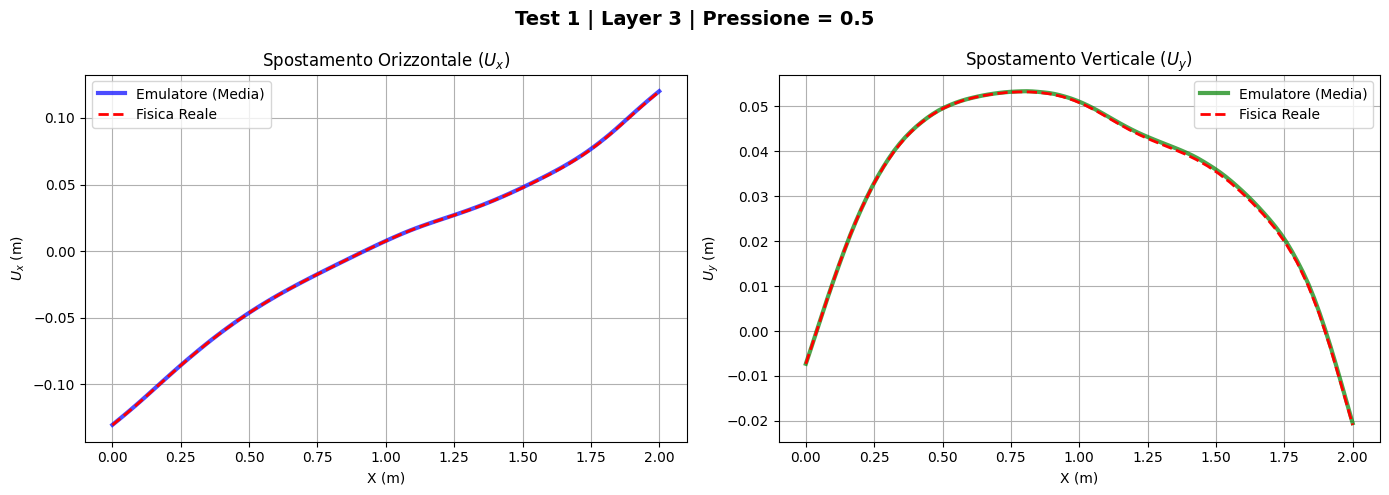


-----------------------------------------------------------------
🔹 TEST 2 | Layer: 2 | Pressione: -0.3
📍 Ground Truth campionato casualmente a: X=0.799, Y=0.493
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...
🚀 Inizio Costruzione Emulatore CP2...
   -> Generazione dataset di addestramento (LHS)...
   -> Avvio 50 simulazioni FEM in parallelo...
   -> Simulazioni completate con successo: 50/50
   -> Addestramento Processi Gaussiani...
   -> Propagazione Incertezza (Monte Carlo su 10.000 campioni)...
✅ Calcolo completato. CI Corner Ux: (1.5800e-02, 1.6545e-02)

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: +1.6111e-02 | CI 90%: [+1.5800e-02, +1.6545e-02] -> ✅ PASSED
   Uy | Reale: -2.9991e-02 | CI 90%: [-3.0308e-02, -2.9406e-02] -> ✅ PASSED


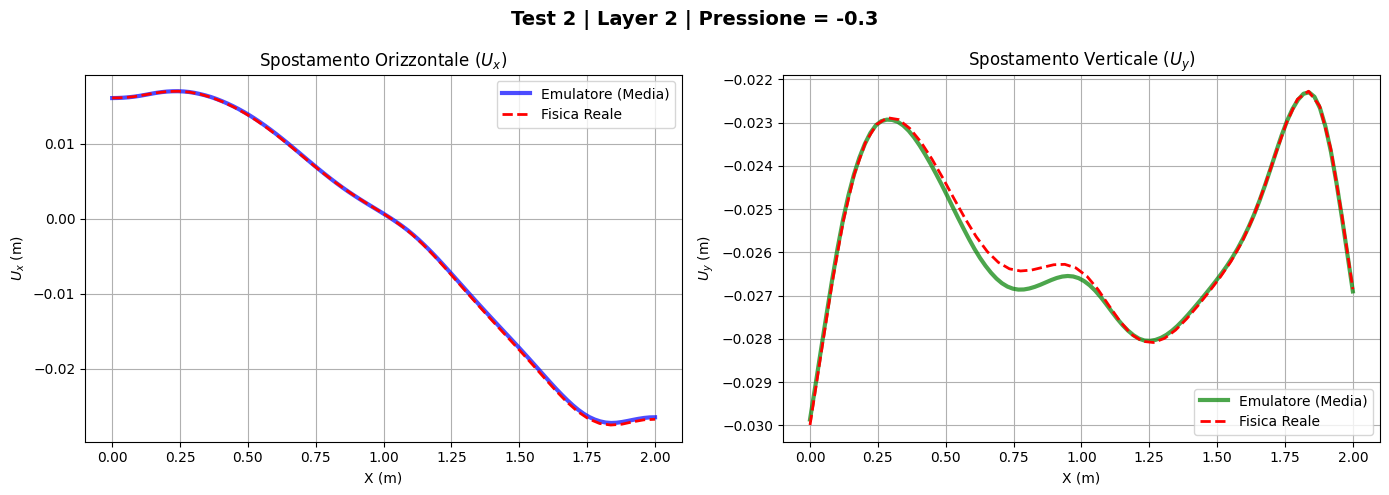


-----------------------------------------------------------------
🔹 TEST 3 | Layer: 4 | Pressione: 0.4
📍 Ground Truth campionato casualmente a: X=1.226, Y=0.378
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...
🚀 Inizio Costruzione Emulatore CP2...
   -> Generazione dataset di addestramento (LHS)...
   -> Avvio 50 simulazioni FEM in parallelo...
   -> Simulazioni completate con successo: 50/50
   -> Addestramento Processi Gaussiani...
   -> Propagazione Incertezza (Monte Carlo su 10.000 campioni)...
✅ Calcolo completato. CI Corner Ux: (-2.9885e-04, -2.9297e-04)

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -2.9662e-04 | CI 90%: [-2.9885e-04, -2.9297e-04] -> ✅ PASSED
   Uy | Reale: -6.6154e-04 | CI 90%: [-6.6516e-04, -6.6138e-04] -> ✅ PASSED


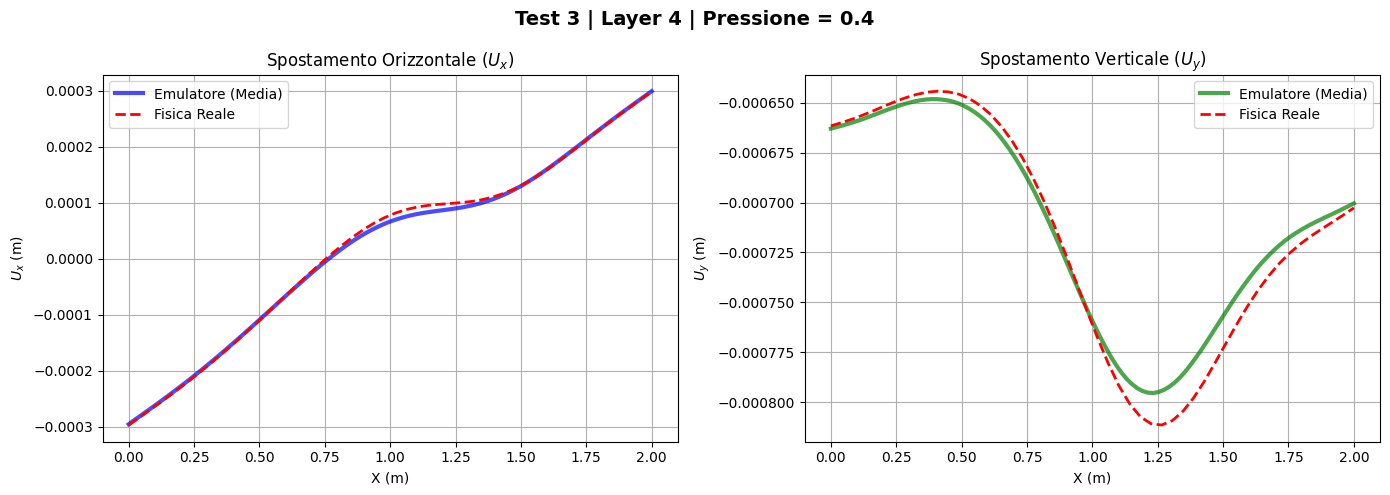


-----------------------------------------------------------------
🔹 TEST 4 | Layer: 3 | Pressione: -0.45
📍 Ground Truth campionato casualmente a: X=0.616, Y=0.608
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...
🚀 Inizio Costruzione Emulatore CP2...
   -> Generazione dataset di addestramento (LHS)...
   -> Avvio 50 simulazioni FEM in parallelo...
   -> Simulazioni completate con successo: 50/50
   -> Addestramento Processi Gaussiani...
   -> Propagazione Incertezza (Monte Carlo su 10.000 campioni)...
✅ Calcolo completato. CI Corner Ux: (1.2619e-01, 1.2915e-01)

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: +1.2796e-01 | CI 90%: [+1.2619e-01, +1.2915e-01] -> ✅ PASSED
   Uy | Reale: +5.5723e-03 | CI 90%: [+4.1803e-03, +6.0541e-03] -> ✅ PASSED


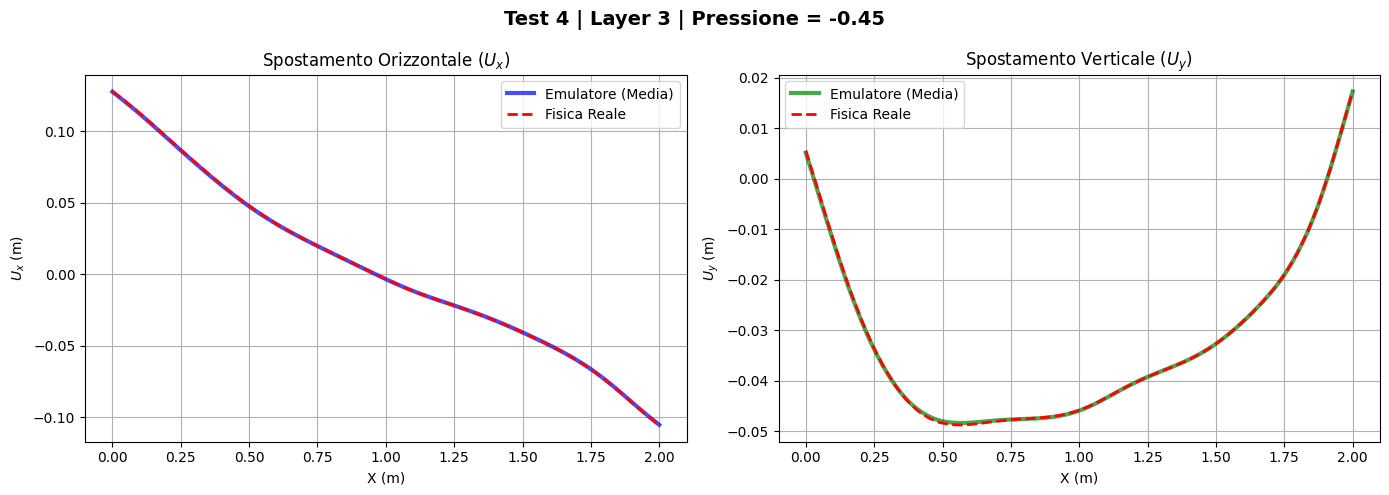


-----------------------------------------------------------------
🔹 TEST 5 | Layer: 1 | Pressione: 0.2
📍 Ground Truth campionato casualmente a: X=0.953, Y=0.402
⏳ Calcolo FEM Ground Truth in corso (alta precisione)...
🚀 Inizio Costruzione Emulatore CP2...
   -> Generazione dataset di addestramento (LHS)...
   -> Avvio 50 simulazioni FEM in parallelo...
   -> Simulazioni completate con successo: 50/50
   -> Addestramento Processi Gaussiani...
   -> Propagazione Incertezza (Monte Carlo su 10.000 campioni)...
✅ Calcolo completato. CI Corner Ux: (-5.7150e-03, -4.1746e-03)

📊 ESITO VALIDAZIONE ANGOLO (0,1):
   Ux | Reale: -5.5948e-03 | CI 90%: [-5.7150e-03, -4.1746e-03] -> ✅ PASSED
   Uy | Reale: +1.9036e-02 | CI 90%: [+1.9043e-02, +1.9990e-02] -> ❌ OUT OF BOUNDS


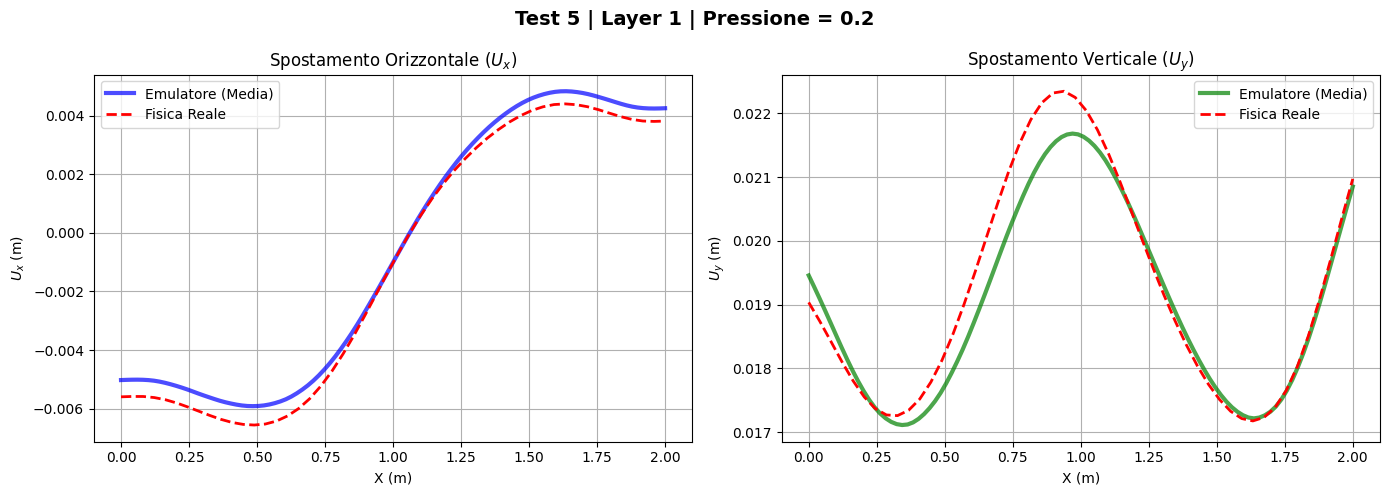

In [7]:
import os
import numpy as np
import tempfile
import matplotlib.pyplot as plt
from pathlib import Path
from contextlib import redirect_stdout
from scipy.interpolate import griddata

# Importiamo il solutore base e il nostro emulatore
from create_grid import create_layered_grid_with_hole
from common_functions import solve_and_export_pressure

def get_ground_truth(cx, cy, layer_ID, pressure_value):
    original_cwd = os.getcwd()
    try:
        with tempfile.TemporaryDirectory() as tmpdir:
            os.chdir(tmpdir)
            with open(os.devnull, 'w') as f, redirect_stdout(f):
                sd, cell_layer = create_layered_grid_with_hole(mesh_size=0.020, center=(cx, cy))
                u = solve_and_export_pressure(
                    sd, cell_layer, layer_ID, pressure_value,
                    folder_export=Path(tmpdir), export_name="gt",
                    cell_data=[("layer", cell_layer.astype(float))]
                )
                nodes = np.column_stack((sd.nodes[0, :], sd.nodes[1, :]))
                
                x_eval = np.linspace(0.0, 2.0, 50)
                target_surf = np.column_stack((x_eval, np.ones_like(x_eval) * 1.0))
                
                ux_surf = griddata(nodes, u[0, :], target_surf, method='linear')
                uy_surf = griddata(nodes, u[1, :], target_surf, method='linear')
                
                corner = np.array([[0.0, 1.0]])
                ux_c = griddata(nodes, u[0, :], corner, method='linear')[0]
                uy_c = griddata(nodes, u[1, :], corner, method='linear')[0]
            os.chdir(original_cwd)
        return ux_surf, uy_surf, ux_c, uy_c
    except Exception as e:
        os.chdir(original_cwd)
        print("Errore nel calcolo del Ground Truth:", e)
        return None, None, None, None

def run_cp2_validation():
    # Fissiamo il seed per rendere i 5 test riproducibili
    # Fixing the seed
    np.random.seed(42)
    
    # Definiamo 5 scenari sintetici perfettamente conformi alle specifiche
    # 5 different scenarios
    test_cases = [
        {"id": 1, "layer": 3, "press":  0.50, "mu": (1.50, 0.25), "std": (0.045, 0.045)}, # Incertezza massima permessa / maximum deviation
        {"id": 2, "layer": 2, "press": -0.30, "mu": (0.80, 0.50), "std": (0.015, 0.015)}, # Incertezza molto bassa / minimum deviation
        {"id": 3, "layer": 4, "press":  0.40, "mu": (1.20, 0.35), "std": (0.030, 0.030)}, 
        {"id": 4, "layer": 3, "press": -0.45, "mu": (0.60, 0.60), "std": (0.020, 0.020)},
        {"id": 5, "layer": 1, "press":  0.20, "mu": (1.00, 0.40), "std": (0.040, 0.040)},
    ]
    
    print("="*65)
    print("🚀 AVVIO VALIDAZIONE INCROCIATA (EMULATORE vs FISICA REALE)")
    print("="*65)
    
    for tc in test_cases:
        print(f"\n" + "-"*65)
        print(f"🔹 TEST {tc['id']} | Layer: {tc['layer']} | Pressione: {tc['press']}")
        
        # 1. Estraiamo un centro REALE campionando dalla distribuzione di incertezza
        # 1. Extract A real center sampling from deviation
        true_cx = np.random.normal(tc['mu'][0], tc['std'][0])
        true_cy = np.random.normal(tc['mu'][1], tc['std'][1])
        print(f"📍 Ground Truth campionato casualmente a: X={true_cx:.3f}, Y={true_cy:.3f}")
        
        # 2. Calcoliamo la Fisica Reale (ora riceviamo 4 valori)
        # 2. Real physics
        print("⏳ Calcolo FEM Ground Truth in corso (alta precisione)...")
        gt_ux_surf, gt_uy_surf, gt_ux_c, gt_uy_c = get_ground_truth(true_cx, true_cy, tc['layer'], tc['press'])
        
        # 3. Interroghiamo l'Emulatore (ci restituisce la FUNZIONE callable f(x))
        # 3. Emulator (gives us the FUNCTION )
        mean_surf_func, CI_corner = GroupSolutionCP2(
            layer_ID=tc['layer'], 
            pressure_value=tc['press'], 
            center_location_mean=tc['mu'], 
            center_location_std=tc['std']
        )
        
        # 4. Verifica Rigorosa (il controllo rimane uguale)
        # 4. Verify: the CI is okay if the TRUE displacement is inside the interval
        ci_ux = CI_corner[0]
        ci_uy = CI_corner[1]
        
        pass_ux = ci_ux[0] <= gt_ux_c <= ci_ux[1]
        pass_uy = ci_uy[0] <= gt_uy_c <= ci_uy[1]
        
        status_ux = "✅ PASSED" if pass_ux else "❌ OUT OF BOUNDS"
        status_uy = "✅ PASSED" if pass_uy else "❌ OUT OF BOUNDS"
        
        print("\n📊 ESITO VALIDAZIONE ANGOLO (0,1):")
        print(f"   Ux | Reale: {gt_ux_c:+.4e} | CI 90%: [{ci_ux[0]:+.4e}, {ci_ux[1]:+.4e}] -> {status_ux}")
        print(f"   Uy | Reale: {gt_uy_c:+.4e} | CI 90%: [{ci_uy[0]:+.4e}, {ci_uy[1]:+.4e}] -> {status_uy}")
        
        # =====================================================================
        # 5. DOPPIO PLOT COMPARATIVO (Subplots affiancati)
        # 5. DOUBLE COMPARATIVE PLOT
        # =====================================================================
        x_plot = np.linspace(0.0, 2.0, 100) # x per l'emulatore / x for emulator
        x_eval = np.linspace(0.0, 2.0, 50)  # x per il ground truth reale / x for ground truth
        
        # Interroghiamo la nostra funzione per separare Ux e Uy
        # Divided Ux and Uy
        ux_pred = [mean_surf_func(xi)[0] for xi in x_plot]
        uy_pred = [mean_surf_func(xi)[1] for xi in x_plot]
        
        # Creiamo un'immagine larga con due grafici (1 riga, 2 colonne)
        fig, axes = plt.subplots(1, 2, figsize=(14, 5))
        fig.suptitle(f"Test {tc['id']} | Layer {tc['layer']} | Pressione = {tc['press']}", fontsize=14, fontweight='bold')
        
        # --- Grafico 1: Spostamento Orizzontale (Ux) ---
        axes[0].plot(x_plot, ux_pred, 'b-', linewidth=3, alpha=0.7, label="Emulatore (Media)")
        axes[0].plot(x_eval, gt_ux_surf, 'r--', linewidth=2, label="Fisica Reale")
        axes[0].set_title("Spostamento Orizzontale ($U_x$)")
        axes[0].set_xlabel("X (m)")
        axes[0].set_ylabel("$U_x$ (m)")
        axes[0].grid(True)
        axes[0].legend()
        
        # --- Grafico 2: Spostamento Verticale (Uy) ---
        axes[1].plot(x_plot, uy_pred, 'g-', linewidth=3, alpha=0.7, label="Emulatore (Media)")
        axes[1].plot(x_eval, gt_uy_surf, 'r--', linewidth=2, label="Fisica Reale")
        axes[1].set_title("Spostamento Verticale ($U_y$)")
        axes[1].set_xlabel("X (m)")
        axes[1].set_ylabel("$U_y$ (m)")
        axes[1].grid(True)
        axes[1].legend()
        
        # Compatta il layout e mostra
        plt.tight_layout()
        plt.show()

if __name__ == '__main__':
    # Protezione multiprocessing necessaria per l'ambiente Jupyter
    import multiprocessing as mp
    try:
        mp.set_start_method('spawn', force=True)
    except RuntimeError:
        pass
        
    run_cp2_validation()

std_x \in (0.01, 0.045)
std_y \in (0.01, 0.045)